In [2]:
import numpy as np 
import matplotlib.pyplot as plt
import control as ctrl 

from IPython.display import display, Markdown

# Define a clean markdown output function that bypasses the text tags
def clean_tf_markdown(self):
    # Extracts only the raw LaTeX fraction from the control library formatting
    latex_string = self._repr_html_().split('>')[-1].strip()
    return latex_string

# Force the TransferFunction class to use our clean LaTeX extractor
ctrl.TransferFunction._repr_markdown_ = clean_tf_markdown


# Plant model

Input : servo angle, output ball position
$$
\ddot x m = \sin(\theta) mg - d \dot x
$$

Linearized

$$
\ddot x m = \theta mg - d \dot x
$$





$$
\frac{g}{(s^2 + s \, d/m)}
$$ 

TransferFunction(
array([0.981]),
array([0.1, 0.1, 0. ]),
outputs=1, inputs=1)

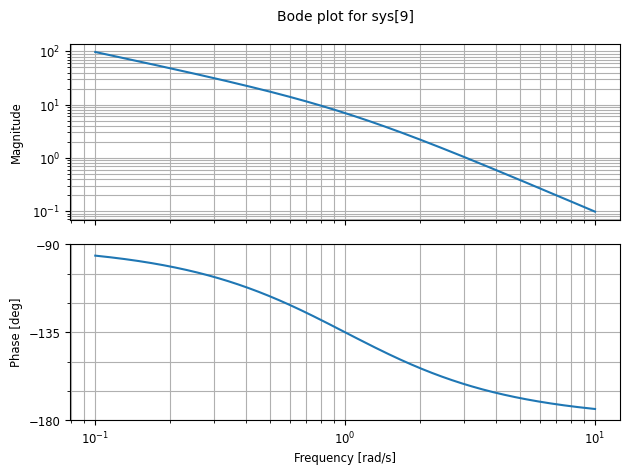

In [3]:
# Params
g = 9.81
d = 0.1
m = 0.1

s = ctrl.tf('s')

G = g/(s**2 + s*d/m)

ctrl.bode(G)

G

# Standard LQR

state vector is only ball pos and velocity, input is board angle $\theta$
$$
\mathrm{x} = 
\begin{bmatrix}
x \\
\dot x
\end{bmatrix}
$$

$$
A = 
\begin{bmatrix}
0 & 1 \\
0 & -d/m
\end{bmatrix}
$$

$$
B = 
\begin{bmatrix}
0  \\
g
\end{bmatrix}
$$

$$
C = 
\begin{bmatrix}
1  & 0
\end{bmatrix}
$$



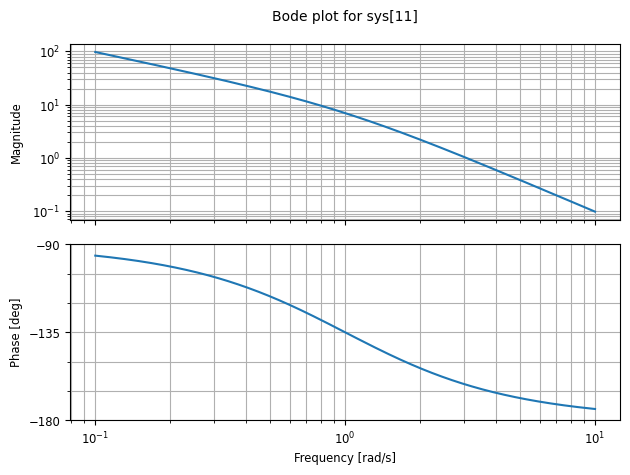

In [4]:

A = np.array([[0,1],
              [0,-d/m]])

B = np.array([[0],
              [g]])

C = np.array([[1,0]])

G = ctrl.ss(A,B,C,0)
ctrl.bode(G)



In [5]:
K = ctrl.lqr(G,np.diag([10,1]),10)[0]
K

array([[1.        , 0.45865638]])

# LQI


Extended with integrated error $e_i$

$$
e_i = \frac{1}{s} (x_r - x)
$$

$$
A_e = 
\begin{bmatrix}
A & 0 \\
C & 0
\end{bmatrix}
$$

$$
B_e = 
\begin{bmatrix}
B \\
0
\end{bmatrix}
$$

$$
\mathrm{u} = 
\begin{bmatrix}
\theta \\
x_r
\end{bmatrix}
$$

Ae
 [[ 0.  1.  0.]
 [ 0. -1.  0.]
 [ 1.  0.  0.]]
Be
 [[0.  ]
 [9.81]
 [0.  ]]
Ce
 [[1 0 0]]


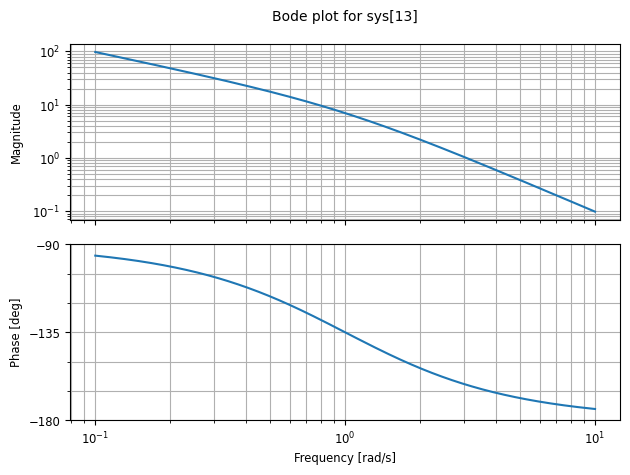

In [6]:

Ae = np.c_[A,[[0], [0]]]
Ae = np.r_[Ae,[[1,0,0]]]
Be = np.r_[B,[[0]]]
Ce = np.c_[C,0]

Ge = ctrl.ss(Ae,Be,Ce,0)
ctrl.bode(Ge)

print("Ae\n",Ae)
print("Be\n",Be)
print("Ce\n",Ce)


In [14]:

KeSOL = ctrl.lqr(Ge,np.diag([10,1,1]),np.diag([10]))
Ke = KeSOL[0]
Ke

array([[1.1721002 , 0.48912276, 0.31622777]])

In [ ]:
# polez of closed loop
KeSOL[2]

array([-2.74015184+1.49906174j, -2.74015184-1.49906174j,
       -0.31799055+0.j        ])

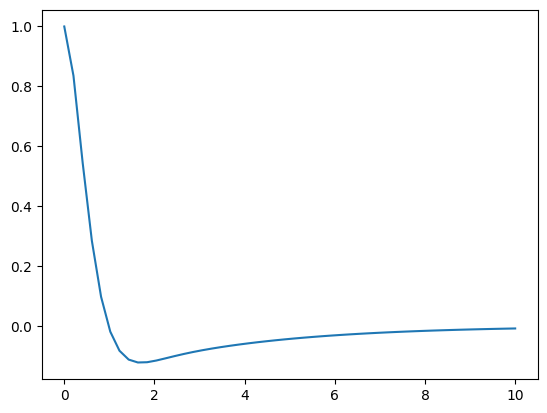

In [20]:
CLe = ctrl.ss((Ae - Be@Ke), [[1],[0],[0]], Ce,0)

plt.figure()

t = np.linspace(0,10)
_,y = ctrl.forced_response(CLe,inputs=0,T=t,initial_state=[1,0,0])

#t,y = ctrl.step_response(CLe)
plt.plot(t,y)